# Sintetici VT e VLP vs traccia registrata (figura 4x1)

Per un evento, una stazione e una componente, tutto nella grandezza `QUANTITY` (velocità di default):

| pannello | contenuto |
|---|---|
| a) | sintetico della soluzione **VT**: 0.075-0.125 Hz (spesso, asse sx) e 0.5-2 Hz (sottile, asse dx) |
| b) | come a) per la soluzione **VLP** |
| c) | somma dei sintetici VT + VLP a bassa frequenza |
| d) | traccia registrata (`DATA/`, counts) con risposta strumentale rimossa, filtrata a bassa frequenza |

Soluzioni: VT da `CAT/catalogue_flegrei_MT_VT.pf`, VLP da `CAT/catalogue_flegrei_composite_MT_LF_std_reloc_best.pf`.

**Catena di processing.** Sintetici e dato registrato passano per gli stessi passi:

1. finestra comune `[OT-T_PAD, OT+T_PAD]` e stesso passo di campionamento (quello dello store GF).
   I sintetici sono estesi ripetendo il primo e l'ultimo campione. Il dato registrato riceve detrend lineare e downsample.
2. stadio a banda larga `Trace.transfer` con gli stessi `FREQLIMITS` e `TFADE`:
   deconvoluzione della risposta strumentale per il dato registrato, sola taper per i sintetici (già nella grandezza fisica).
3. Butterworth **causale** `lowpass(ORDER, fmax)` + `highpass(ORDER, fmin)`, come in `filter_VLP_traces.py`.
4. taglio alla finestra del plot.

In [63]:
import os
import glob
import logging

import numpy as np
import matplotlib.pyplot as plt

from pyrocko import io, model, trace, util, orthodrome
from pyrocko.io import stationxml
from pyrocko.gf import LocalEngine, Target, MTSource, HalfSinusoidSTF, ResonatorSTF

%matplotlib inline

## 1. Selezione e parametri

In [64]:
# ----------------------------------------------------------------------------
# SELEZIONE
# ----------------------------------------------------------------------------
EVENT_NAME = 'flegrei_2023_06_11_06_44_25'     # CHANGE
STATION    = 'CMIS'                            # CHANGE
CHANNEL    = 'HHN'                             # CHANGE: componente di riferimento (ultima lettera N, E o Z)
NETWORK    = 'IV'

QUANTITY = 'velocity'       # 'velocity' o 'displacement', per sintetici e dato registrato

# asse x comune, rispetto all'origin time [s]
T_BEFORE = 10.      # prima di OT
T_AFTER  = 90.      # dopo OT (1 min 30 s)

# ----------------------------------------------------------------------------
# FILTRI
# ----------------------------------------------------------------------------
FMIN_LF, FMAX_LF = 0.075, 0.125     # bassa frequenza [Hz]
FMIN_HF, FMAX_HF = 0.5, 2.0         # alta frequenza [Hz]
ORDER = 4                           # poli del Butterworth causale

# stadio comune a banda larga (taper coseno in frequenza) [Hz]:
# stabilizza la deconvoluzione, non tocca le due bande di interesse
FREQLIMITS = (0.01, 0.02, 8., 9.5)
TFADE = 50.                         # taper nel tempo agli estremi della finestra di processing [s]
T_PAD = 300.                        # finestra di processing [OT-T_PAD, OT+T_PAD] = i 10 min in DATA

# ----------------------------------------------------------------------------
# SINTETICI (stesse scelte dell'inversione grond composite)
# ----------------------------------------------------------------------------
STORE_ID = 'campiflegrei_near_0_dist'
INTERPOLATION = 'multilinear'
VT_STF_DURATION = 0.1               # [s] HalfSinusoidSTF, duration fissa nel subproblem vt
# i cataloghi riportano il tempo di riferimento, non i vt.time/vlp.time best di grond
# (per flegrei_2023_06_11: -0.011 s e +0.295 s, da stats.yaml): eventuale correzione [s]
VT_TIME_SHIFT = 0.
VLP_TIME_SHIFT = 0.

# ----------------------------------------------------------------------------
# RISPOSTA STRUMENTALE
# ----------------------------------------------------------------------------
# 'stations_flegrei_INGV_final.xml' e' l'originale (usato finora da grond): per CAAM, CBAC,
# CFMN, CMIS e SORR ha il polo -0.0392-850.7j al posto di -392-850.7j (vedi note in fondo)
STATIONXML_FILE = 'stations_flegrei_INGV_final.xml'       #stations_flegrei_INGV_final_corrected

# ----------------------------------------------------------------------------
# GRAFICA
# ----------------------------------------------------------------------------
COLORS = {
    'VT':  '#0362a4',     # rosso scuro
    'VLP': "#ee6623",     # blu
    'SUM': "#BD2025",     # rosso
    'OBS': '#555555',     # grigio scuro
    'OT':  '#3a3a3a',     # linea dell'origin time
}
LW = {'LF': 3.5, 'HF': 2.0, 'SUM': 5., 'OBS': 5., 'OT': 1.5}
ALPHA_HF = 0.6             # trasparenza delle tracce 0.5-2 Hz
SHARE_LF_YLIM = True        # stessa scala per tutti gli assi sx (0.075-0.125 Hz)
SHARE_HF_YLIM = True        # stessa scala per tutti gli assi dx (0.5-2 Hz)
FIGSIZE = (12, 13)

SAVE_FIG = True
FIG_FORMATS = ('pdf','png')

In [65]:
workdir = '..'

catname_VT  = os.path.join(workdir, 'CAT', 'catalogue_flegrei_MT_VT.pf')
catname_VLP = os.path.join(workdir, 'CAT', 'catalogue_flegrei_composite_MT_LF_std_reloc_best.pf')
stations_name = os.path.join(workdir, 'META_DATA', 'stations_flegrei_INGV_final.pf')
stationxml_name = os.path.join(workdir, 'META_DATA', STATIONXML_FILE)
datadir = os.path.join(workdir, 'DATA')
gfdir   = os.path.join(workdir, 'GF_STORES')
plotdir = os.path.join(workdir, 'PLOTS', 'SYNTH')

# unita' di ingresso per la risposta (fake_input_units) ed etichetta degli assi
QUANTITIES = {
    'displacement': ('M', 'Displacement [m]'),
    'velocity':     ('M/S', 'Velocity [m/s]'),
}
if QUANTITY not in QUANTITIES:
    raise ValueError(f'QUANTITY deve essere una tra {list(QUANTITIES)}')
input_units, ylabel = QUANTITIES[QUANTITY]


def get_event(events, name, catname):
    for ev in events:
        if ev.name == name:
            return ev
    raise ValueError(f'evento {name} non trovato in {catname}')


def get_tag(ev, key):
    '''Legge un valore numerico dai tags dell'evento (es. "frequency:0.114").'''
    for tag in ev.tags:
        if tag.startswith(key + ':'):
            return float(tag.split(':', 1)[1])
    raise ValueError(f'tag "{key}" mancante per {ev.name}')


events_VT  = model.load_events(catname_VT)
events_VLP = model.load_events(catname_VLP)
names_VLP = {ev.name for ev in events_VLP}
print('Eventi presenti in entrambi i cataloghi:')
print('  ' + '\n  '.join(ev.name for ev in events_VT if ev.name in names_VLP))

ev_VT  = get_event(events_VT, EVENT_NAME, catname_VT)
ev_VLP = get_event(events_VLP, EVENT_NAME, catname_VLP)
vlp_freq = get_tag(ev_VLP, 'frequency')
t_ot = ev_VT.time

st = next((s for s in model.load_stations(stations_name) if s.station == STATION), None)
if st is None:
    raise ValueError(f'stazione {STATION} non trovata in {stations_name}')

if CHANNEL[-1] not in 'NEZ':
    raise ValueError(f'componente {CHANNEL}: serve un canale che finisca per N, E o Z')

# traccia registrata (DATA contiene counts grezzi)
trs_obs = []
for fn in sorted(glob.glob(os.path.join(datadir, EVENT_NAME, '*.mseed'))):
    trs_obs.extend(io.load(fn))
trs_obs = trace.degapper(trs_obs, maxgap=5, fillmethod='interpolate')

nslc = (NETWORK, STATION, '', CHANNEL)
sel = [tr for tr in trs_obs if tr.nslc_id == nslc]
if not sel:
    available = sorted({'.'.join(tr.nslc_id) for tr in trs_obs})
    raise ValueError(f'{".".join(nslc)} non presente in DATA/{EVENT_NAME}. Disponibili:\n' + ', '.join(available))
if len(sel) > 1:
    print(f'ATTENZIONE: {len(sel)} segmenti per {".".join(nslc)}, uso il piu\' lungo')
tr_obs_raw = max(sel, key=lambda tr: tr.tmax - tr.tmin)

print(f'\nOrigin time: {util.time_to_str(t_ot)}')
print(f'Stazione:    {".".join(nslc)}  ({st.lat:.4f}, {st.lon:.4f})')
print(f'Registrata:  {util.time_to_str(tr_obs_raw.tmin)} -> {util.time_to_str(tr_obs_raw.tmax)}, dt = {tr_obs_raw.deltat} s')
print(f'Grandezza:   {QUANTITY}')

Eventi presenti in entrambi i cataloghi:
  flegrei_2018_09_18_21_36_41
  flegrei_2023_06_11_06_44_25
  flegrei_2023_09_26_07_10_29
  flegrei_2023_10_02_20_08_26
  flegrei_2024_04_27_03_44_56
  flegrei_2024_05_22_06_28_00
  flegrei_2024_06_08_01_52_04
  flegrei_2024_06_18_01_58_24
  flegrei_2024_07_26_11_46_21
  flegrei_2024_08_30_19_23_15
  flegrei_2025_02_16_14_30_02
  flegrei_2025_03_13_00_25_02
  flegrei_2025_06_30_10_47_11
  flegrei_2025_07_18_07_14_22
  flegrei_2025_08_28_19_53_23
  flegrei_2025_09_01_15_22_01
  flegrei_2025_10_12_13_35_50
  flegrei_2026_05_21_03_50_52
  flegrei_2026_07_31_20_00_09

Origin time: 2023-06-11 06:44:25.720
Stazione:    IV.CMIS..HHN  (40.7782, 14.0890)
Registrata:  2023-06-11 06:39:25.720 -> 2023-06-11 06:49:25.720, dt = 0.01 s
Grandezza:   velocity


## 2. Sintetici

- **VT**: `HalfSinusoidSTF(duration=0.1 s)`, come nel subproblem `vt` di grond.
- **VLP**: `ResonatorSTF` con `duration` e `frequency` presi dal catalogo.
  `MTSource.from_pyrocko_event` da solo creerebbe una `HalfSinusoidSTF` di 24.7 s a partire da `duration`, quindi la STF va passata esplicitamente.

Il target riceve il codice del canale: pyrocko ne ricava l'orientazione, cioè N = azimuth 0°, E = 90°, Z = verso l'alto.
`quantity` va data esplicitamente: senza, pyrocko la dedurrebbe dal codice del canale (`HH?` → velocità).

In [66]:
engine = LocalEngine(store_superdirs=[gfdir])

target = Target(
    codes=nslc,
    lat=st.lat, lon=st.lon,
    store_id=STORE_ID,
    interpolation=INTERPOLATION,
    quantity=QUANTITY)

src_VT = MTSource.from_pyrocko_event(
    ev_VT, stf=HalfSinusoidSTF(duration=VT_STF_DURATION))
src_VLP = MTSource.from_pyrocko_event(
    ev_VLP, stf=ResonatorSTF(duration=ev_VLP.duration, frequency=vlp_freq))
src_VT.time += VT_TIME_SHIFT
src_VLP.time += VLP_TIME_SHIFT

response = engine.process([src_VT, src_VLP], [target])
tr_VT_raw, tr_VLP_raw = [tr for _, _, tr in response.iter_results()]

for label, ev, src, tr in (('VT', ev_VT, src_VT, tr_VT_raw), ('VLP', ev_VLP, src_VLP, tr_VLP_raw)):
    dist = orthodrome.distance_accurate50m(ev, st)
    print(f'{label:4s} Mw {ev.magnitude:.2f} | depth {ev.depth/1e3:.2f} km | epic. dist {dist/1e3:.2f} km | '
          f'{src.stf} | synth {tr.tmin - t_ot:+.1f} .. {tr.tmax - t_ot:+.1f} s, dt {tr.deltat} s')

VT   Mw 2.93 | depth 3.55 km | epic. dist 6.49 km | --- !pf.HalfSinusoidSTF
duration: 0.1
anchor: 0.0
exponent: 1
 | synth -7.9 .. +26.5 s, dt 0.05 s
VLP  Mw 1.62 | depth 3.74 km | epic. dist 6.78 km | --- !pf.ResonatorSTF
duration: 24.7125
frequency: 0.11413527
 | synth -7.8 .. +100.9 s, dt 0.05 s


## 3. Traccia registrata: risposta strumentale

In [67]:
# i warning di pyrocko sulla sensibilita' sono sostituiti dal controllo esplicito qui sotto
logging.getLogger('pyrocko.io.stationxml').setLevel(logging.ERROR)

sx = stationxml.load_xml(filename=stationxml_name)
resp_obs = sx.get_pyrocko_response(nslc, time=t_ot, fake_input_units=input_units)

# |H| calcolato dai poli e zeri deve coincidere con la sensibilita' dichiarata nell'XML
print(f'StationXML: {STATIONXML_FILE}')
for cp in resp_obs.checkpoints:
    ratio = abs(resp_obs.evaluate(np.array([cp.frequency]))[0]) / cp.value
    flag = 'OK' if abs(ratio - 1.) < 0.02 else 'ATTENZIONE: poli/zeri incoerenti con la sensibilita\''
    print(f'|H({cp.frequency:g} Hz)| / sensibilita\' dichiarata = {ratio:.4f}  {flag}')

StationXML: stations_flegrei_INGV_final.xml
|H(1 Hz)| / sensibilita' dichiarata = 1.0997  ATTENZIONE: poli/zeri incoerenti con la sensibilita'


## 4. Processing e filtraggio (identico per sintetici e registrato)

In [68]:
deltat = tr_VT_raw.deltat             # passo dello store GF
tmin_proc, tmax_proc = t_ot - T_PAD, t_ot + T_PAD


def detrend(tr):
    '''Rimuove media e trend lineare (in place).'''
    y = tr.ydata.astype(np.float64)
    x = np.arange(y.size, dtype=np.float64)
    slope, offset = np.polyfit(x, y, 1)
    tr.set_ydata(y - (slope*x + offset))


def broadband(tr, resp=None):
    '''Stadio comune: demean, taper TFADE nel tempo, taper coseno FREQLIMITS.

    Con resp deconvolve la risposta (counts -> QUANTITY); i sintetici sono gia'
    nella grandezza fisica e ricevono solo le taper.
    '''
    return tr.transfer(tfade=TFADE, freqlimits=FREQLIMITS, transfer_function=resp,
                       invert=True, cut_off_fading=False)


def bandpass(tr, fmin, fmax):
    '''Butterworth causale ORDER poli: lowpass(fmax) + highpass(fmin).'''
    tr = tr.copy()
    tr.lowpass(ORDER, fmax, demean=False)
    tr.highpass(ORDER, fmin, demean=False)
    return tr


def cut(tr):
    return tr.chop(t_ot - T_BEFORE - tr.deltat, t_ot + T_AFTER + tr.deltat, inplace=False)


# 1. stessa finestra e stesso dt
proc = {}
for key, tr in (('VT', tr_VT_raw), ('VLP', tr_VLP_raw)):
    tr = tr.copy()
    tr.extend(tmin_proc, tmax_proc, fillmethod='repeat')
    proc[key] = tr

tr = tr_obs_raw.chop(tmin_proc, tmax_proc, inplace=False)
if tr.tmin > t_ot - T_BEFORE - 120. or tr.tmax < t_ot + T_AFTER:
    print('ATTENZIONE: il dato registrato copre poco prima della finestra, possibili transitori del filtro')
detrend(tr)
tr.downsample_to(deltat, snap=True, demean=False)
proc['OBS'] = tr

# 2. stadio a banda larga (per il registrato: counts -> QUANTITY)
proc = {key: broadband(tr, resp_obs if key == 'OBS' else None) for key, tr in proc.items()}

# 3. + 4. filtri e taglio
lf = {key: cut(bandpass(tr, FMIN_LF, FMAX_LF)) for key, tr in proc.items()}
hf = {key: cut(bandpass(proc[key], FMIN_HF, FMAX_HF)) for key in ('VT', 'VLP')}

# somma VT + VLP a bassa frequenza (il filtro e' lineare: equivale a filtrare la somma)
lf['SUM'] = lf['VT'].copy()
lf['SUM'].add(lf['VLP'])

unit = ylabel.split('[')[1].rstrip(']')
for name, d in (('LF', lf), ('HF', hf)):
    for key, tr in d.items():
        print(f'{name} {key:4s} picco = {np.abs(tr.ydata).max():.3e} {unit}')

LF VT   picco = 1.799e-06 m/s
LF VLP  picco = 6.718e-07 m/s
LF OBS  picco = 2.754e-06 m/s
LF SUM  picco = 2.009e-06 m/s
HF VT   picco = 1.595e-04 m/s
HF VLP  picco = 7.202e-07 m/s


## 5. Figura

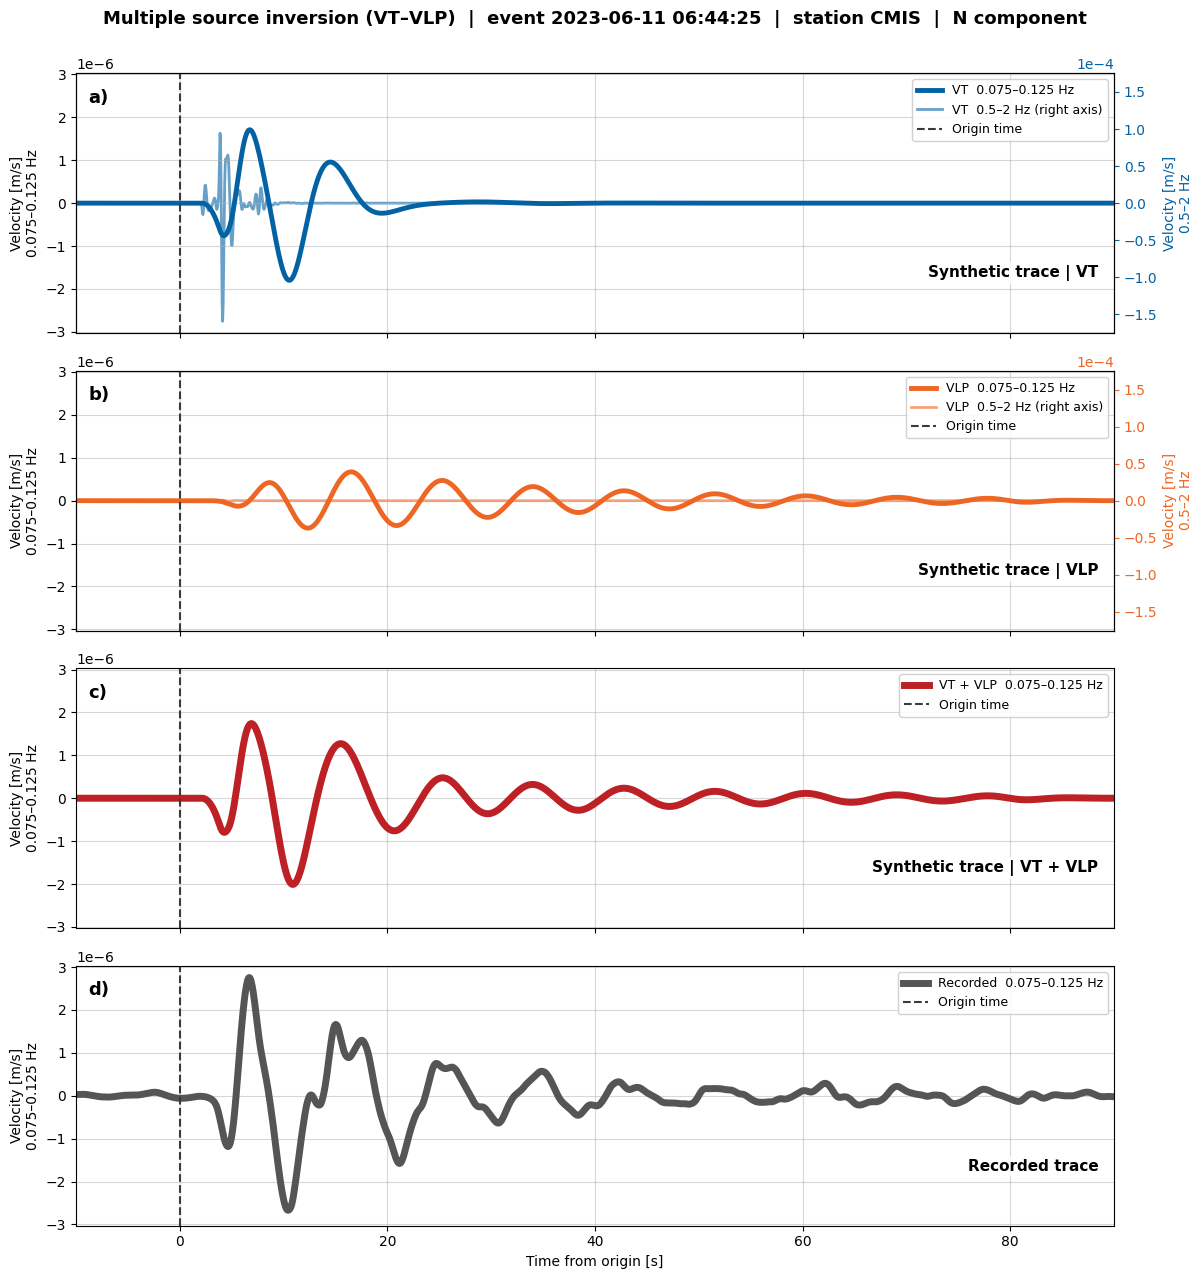

In [69]:
comp = CHANNEL[-1]
ot_str = util.time_to_str(t_ot, format='%Y-%m-%d %H:%M:%S')
band_lf = f'{FMIN_LF:g}–{FMAX_LF:g} Hz'
band_hf = f'{FMIN_HF:g}–{FMAX_HF:g} Hz'


def rel_time(tr):
    return tr.get_xdata() - t_ot


def sym_lim(*trs, pad=1.1):
    return pad * max(np.abs(tr.ydata).max() for tr in trs)


panels = [
    dict(lf=lf['VT'], hf=hf['VT'], color=COLORS['VT'], lw=LW['LF'], label='VT',
         title='Synthetic trace | VT',
         info=f'Mw {ev_VT.magnitude:.2f}, depth {ev_VT.depth/1e3:.2f} km'),
    dict(lf=lf['VLP'], hf=hf['VLP'], color=COLORS['VLP'], lw=LW['LF'], label='VLP',
         title='Synthetic trace | VLP',
         info=f'f = {vlp_freq:.3f} Hz, τ = {ev_VLP.duration:.1f} s, depth {ev_VLP.depth/1e3:.2f} km'),
    dict(lf=lf['SUM'], hf=None, color=COLORS['SUM'], lw=LW['SUM'], label='VT + VLP',
         title='Synthetic trace | VT + VLP',
         info=f'sum of panels a) and b), {band_lf}'),
    dict(lf=lf['OBS'], hf=None, color=COLORS['OBS'], lw=LW['OBS'], label='Recorded',
         title='Recorded trace',
         info=f'{".".join(c for c in nslc if c)}, restituted to {QUANTITY}'),
]

ylim_lf_all = sym_lim(*(p['lf'] for p in panels))
ylim_hf_all = sym_lim(*(p['hf'] for p in panels if p['hf'] is not None))
text_box = dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2)

fig, axes = plt.subplots(4, 1, figsize=FIGSIZE, sharex=True)

for ax, letter, p in zip(axes, 'abcd', panels):
    handles = []

    # traccia 0.5-2 Hz sull'asse destro
    if p['hf'] is not None:
        axr = ax.twinx()
        h, = axr.plot(rel_time(p['hf']), p['hf'].ydata, color=p['color'],
                      lw=LW['HF'], alpha=ALPHA_HF, label=f"{p['label']}  {band_hf} (right axis)")
        handles.append(h)
        ylim = ylim_hf_all if SHARE_HF_YLIM else sym_lim(p['hf'])
        axr.set_ylim(-ylim, ylim)
        axr.set_ylabel(f'{ylabel}\n{band_hf}', color=p['color'])
        axr.tick_params(axis='y', colors=p['color'])
        axr.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
        axr.yaxis.get_offset_text().set_color(p['color'])
        # la traccia a bassa frequenza resta sopra quella ad alta frequenza
        ax.set_zorder(axr.get_zorder() + 1)
        ax.patch.set_visible(False)

    # traccia 0.075-0.125 Hz sull'asse sinistro
    h, = ax.plot(rel_time(p['lf']), p['lf'].ydata, color=p['color'], lw=p['lw'],
                 label=f"{p['label']}  {band_lf}")
    handles.insert(0, h)
    handles.append(ax.axvline(0., color=COLORS['OT'], lw=LW['OT'], ls='--', label='Origin time'))

    ylim = ylim_lf_all if SHARE_LF_YLIM else sym_lim(p['lf'])
    ax.set_ylim(-ylim, ylim)
    ax.set_ylabel(f'{ylabel}\n{band_lf}')
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    ax.grid(True, alpha=0.5)
    ax.legend(handles=handles, loc='upper right', fontsize=9, framealpha=0.9)

    # didascalie
    ax.text(0.012, 0.94, f'{letter})', transform=ax.transAxes, fontsize=13,
            fontweight='bold', va='top')
    ax.text(0.985, 0.20, p['title'], transform=ax.transAxes, ha='right', va='bottom',
            fontsize=11, fontweight='bold', bbox=text_box)
    #ax.text(0.985, 0.06, p['info'], transform=ax.transAxes, ha='right', va='bottom',
    #        fontsize=10, bbox=text_box)

axes[-1].set_xlim(-T_BEFORE, T_AFTER)
axes[-1].set_xlabel('Time from origin [s]')
fig.suptitle(f'Multiple source inversion (VT–VLP)  |  event {ot_str}  |  '
             f'station {STATION}  |  {comp} component',
             fontsize=13, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

In [70]:
if SAVE_FIG:
    os.makedirs(plotdir, exist_ok=True)
    base = os.path.join(plotdir, f'{EVENT_NAME}_{STATION}_{CHANNEL}_VT_VLP_synth_obs_{QUANTITY}')
    for ext in FIG_FORMATS:
        fig.savefig(f'{base}.{ext}', dpi=300, bbox_inches='tight')
        print('salvata:', f'{base}.{ext}')

salvata: ../PLOTS/SYNTH/flegrei_2023_06_11_06_44_25_CMIS_HHN_VT_VLP_synth_obs_velocity.pdf
salvata: ../PLOTS/SYNTH/flegrei_2023_06_11_06_44_25_CMIS_HHN_VT_VLP_synth_obs_velocity.png


In [71]:
# didascalia proposta (in inglese, come le etichette della figura)
caption = (
    f'{comp}-component ground {QUANTITY} at station {STATION} for the {ot_str} UTC event. '
    f'(a) Synthetic seismogram of the VT moment tensor solution, band-pass filtered at {band_lf} '
    f'(thick line, left axis) and {band_hf} (thin line, right axis). '
    f'(b) Same for the VLP solution (resonator source time function, f = {vlp_freq:.3f} Hz, '
    f'τ = {ev_VLP.duration:.1f} s). '
    f'(c) Sum of the low-frequency VT and VLP synthetics. '
    f'(d) Recorded seismogram, corrected for the instrument response and filtered at {band_lf}. '
    f'Synthetics and data share the same processing (causal {ORDER}-pole Butterworth filters). '
    f'All left axes share one scale, all right axes another. '
    f'The dashed line marks the origin time.'
)
print(caption)

N-component ground velocity at station CMIS for the 2023-06-11 06:44:25 UTC event. (a) Synthetic seismogram of the VT moment tensor solution, band-pass filtered at 0.075–0.125 Hz (thick line, left axis) and 0.5–2 Hz (thin line, right axis). (b) Same for the VLP solution (resonator source time function, f = 0.114 Hz, τ = 24.7 s). (c) Sum of the low-frequency VT and VLP synthetics. (d) Recorded seismogram, corrected for the instrument response and filtered at 0.075–0.125 Hz. Synthetics and data share the same processing (causal 4-pole Butterworth filters). All left axes share one scale, all right axes another. The dashed line marks the origin time.


## Note

- **Risposta strumentale.** In `stations_flegrei_INGV_final.xml` il polo coniugato di `-392+850.7j` è scritto `-0.0392-850.7j`.
  Riguarda CAAM, CBAC, CFMN, CMIS e SORR (canali HH*); CQUE HN* ha un errore simile (`-9738.94j` invece di `-973.894j`).
  Con il polo sbagliato |H| risulta più grande del 10% rispetto alla sensibilità dichiarata e la fase ruota di circa 25°.
  `stations_flegrei_INGV_final_corrected.xml` contiene il polo giusto.
  Grond legge il file originale (`responses_stationxml_paths` nei `.gronf`), quindi le inversioni su queste stazioni ne risentono.
- **`DATA_RESPONSE/` è in velocità.** `remove_intrument_response.ipynb` usa `output="VEL"` e l'XML originale.
  Il pannello d) della vecchia `FIG_3` confrontava quindi una velocità, etichettata "Displacement [m]", con sintetici in spostamento.
- **`ResonatorSTF` non è normalizzata.** Negli store pyrocko la STF è il tasso di momento: le GF sono la risposta a un gradino di momento.
  `HalfSinusoidSTF` ha campioni che sommano a 1, quindi M0 è il momento finale.
  `ResonatorSTF` invece usa `exp(-t/τ)·sin(2πft)` così com'è: con lo store a 20 Hz la somma dei campioni vale circa 26-29.
  Il momento dei sintetici VLP è quindi circa 27 × M0 del catalogo, circa +0.95 in Mw.
  Il fattore dipende dal passo dello store e vale circa 1/(2πf·dt).
  La STF viene inoltre troncata a 3τ, e da qui viene il piccolo impulso a 0.5-2 Hz verso 3τ + 4 s dopo OT.
- **Tempi.** I due cataloghi hanno lo stesso tempo di riferimento per VT e VLP; gli offset best di grond (`vt.time`, `vlp.time`) non sono salvati.
  `VT_TIME_SHIFT` e `VLP_TIME_SHIFT` servono a reintrodurli.